#**Modulo V Imágenes en salud**

Dras. Valeria Rulloni- Carolina Maldonado

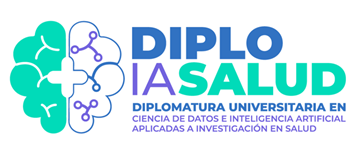

 **Diplomatura en Ciencia de Datos e Inteligencia Artificial
Aplicada a la Investigación en Salud**
Sitio web: https://diploiasalud.sitios.fcm.unc.edu.ar/

# Temario a desarrollar:


1. Imágenes digitales. Estructura. Tipo de dato: float,
uint8, logical. Imágenes binarias, monocromáticas, a color.
2. Histograma. Mejora de la imagen:Transformaciones punto a punto,Umbralado y Binarización.
3. **Ruido. Filtros. Noción de Vecindad. Filtros lineales. Filtros estadísticos.**
4. Práctica integral: Mejora y segmentación. Algoritmos de ML en imágenes (Introducción)


**Recomendación:**
+ Antes que nada **realice una copia de este archivo y trabaje en ella** . Guárdelo en la misma carpeta de preferencia (si está en Colaboratory lo guarda por defecto en la carpeta Colaboratory del drive, se puede reubicar).

# Ruido en imágenes

Imagen puede degradarse por ruido (interferencias por ejemplo). Uno espera ver la imagen original I(x,y), pero suele tener alguna degradación y se observa Iobservada(x,y)

**Tipos de ruido:**

## Multiplicativo Speckle:

$$Iobs(x,y)=I(x,y)*n(x,y)$$, donde n(x,y) aleatorio. común en imágenes de ultrasonido. Se ven imágenes moteadas.

[fuente](https://ameultrasounds.com/blogs/ultrasound-series/speckle-reduction-imaging?srsltid=AfmBOooxs_g58_5qz3YJfc0m4sj2CpMKobISiHqfLT4q4MBBN3N7ssZR)

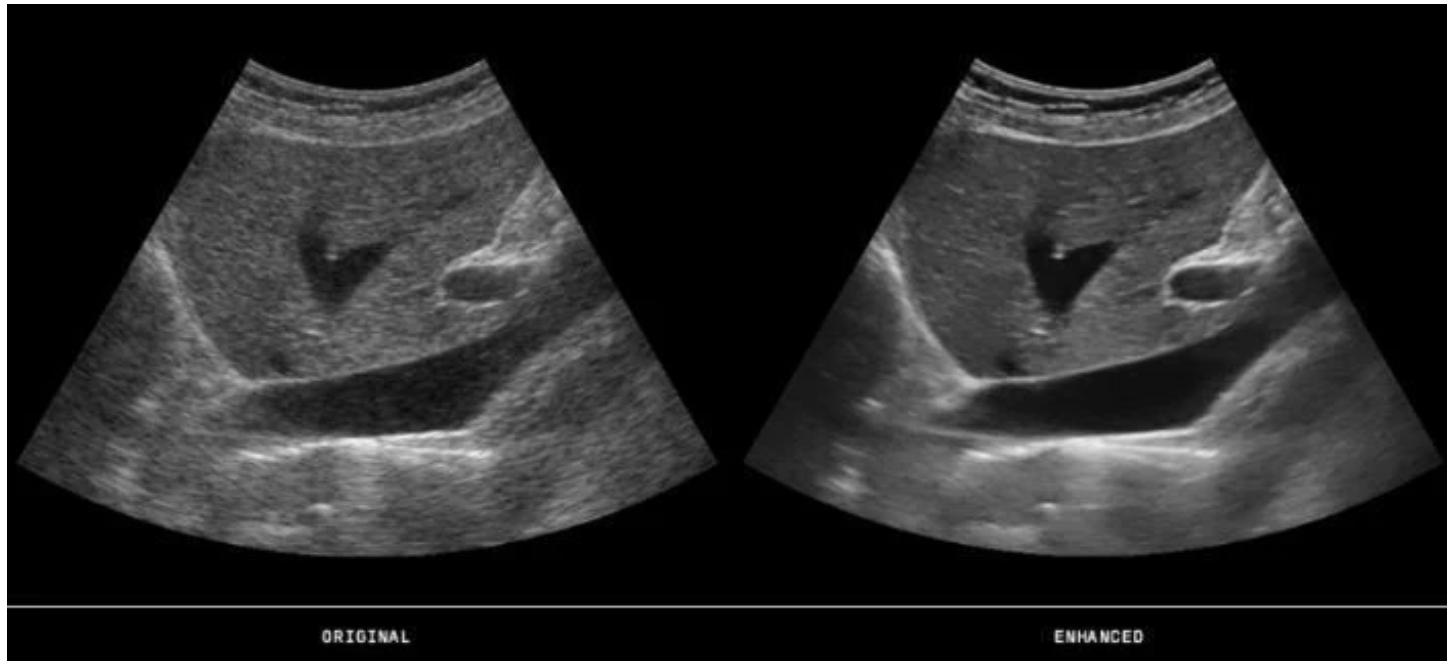

## Ruido Aditivo gaussiano:

$$I_{obs}=I(x,y)+n(x,y),$$

donde $n(x,y)\sim N(0,\sigma)$

aleatorio indep. con distribución normal con media $0$ y desvío $\sigma$ en general desconocido (también llamado **ruido blanco**). El más común.


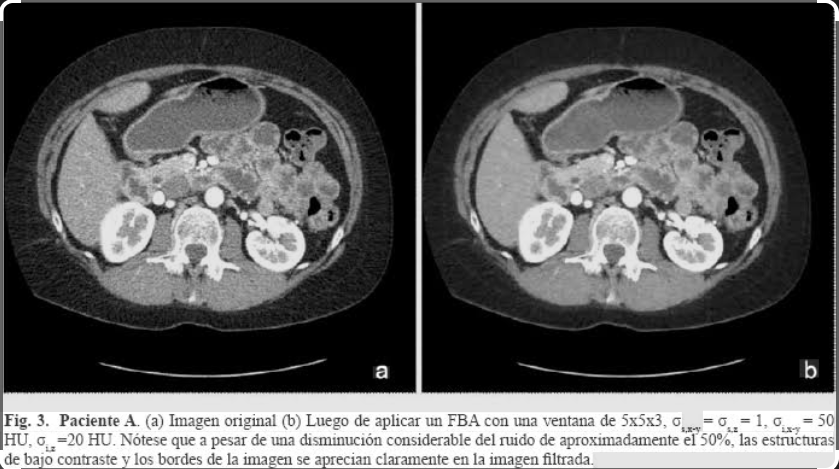


## Ruido Sal y pimienta:

-para imágenes con intensidades en [0,1]:


  
$$I_{obs}(x,y)=\begin{cases}
    I(x,y) &  \\
    1  & blanco, sal
    \\
    0  & negro, pimienta
\end{cases}
$$


-para imágenes con intensidades en [0,255]:

$$I_{obs}=
\begin{cases}
    I(x,y) &  \\
    255  & blanco, sal
    \\
    0  & negro, pimienta
\end{cases}
$$


### Práctica

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
imagen_ruido1= cv2.imread('/content/imagen_ruido_1.png',0) #abrimos imagen en monocroma
imagen_ruido2= cv2.imread('/content/imagen_ruido_2.png',0) #abrimos imagen en monocroma
imagen_sin_ruido= cv2.imread('/content/imagen_original.png',0) #abrimos imagen en monocroma
#verificamos dimensiones
print(imagen_ruido1.shape)
print(imagen_ruido2.shape)
print(imagen_sin_ruido.shape)

(275, 557)
(275, 557)
(275, 557)


Imágenes recortadas y corrompidas de la original proveniente de [fuente](https://pans.org.pk/category/blog/weekly-image-challenge/)

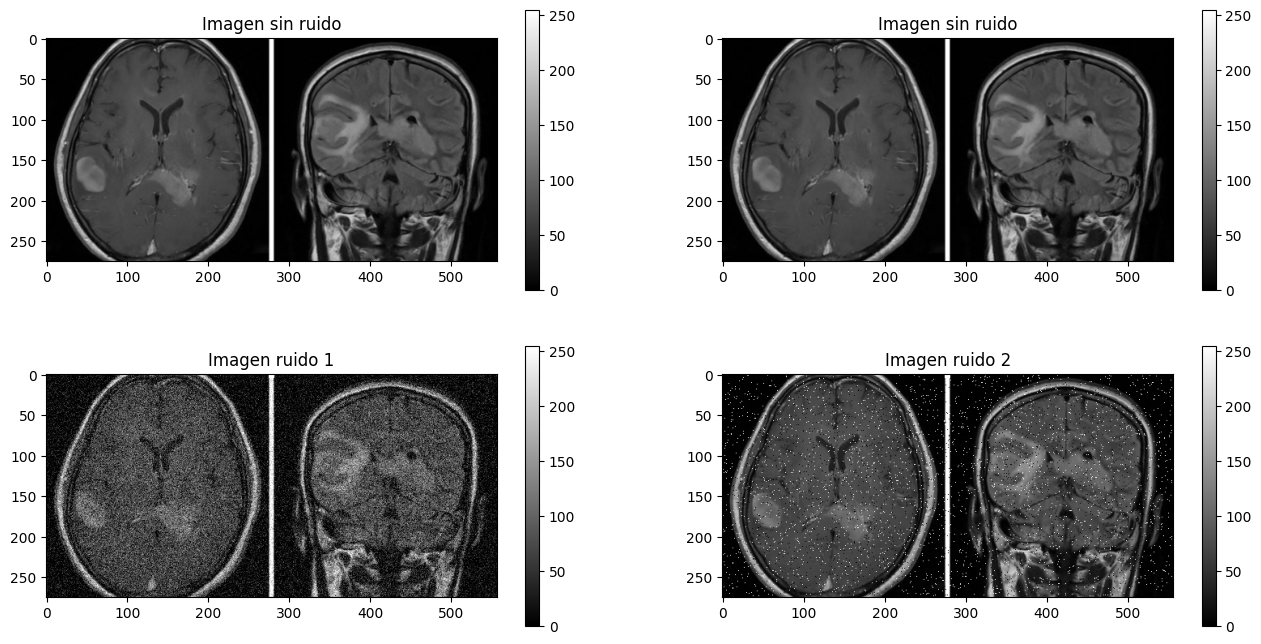

In [3]:
#Graficamos ambas imágenes
plt.figure(figsize=(16,8))
plt.subplot(221),plt.imshow(imagen_sin_ruido, cmap = 'gray')
plt.colorbar()
plt.title('Imagen sin ruido')
plt.subplot(222),plt.imshow(imagen_sin_ruido, cmap = 'gray')
plt.colorbar()
plt.title('Imagen sin ruido')
plt.subplot(223),plt.imshow(imagen_ruido1, cmap = 'gray')
plt.colorbar()
plt.title('Imagen ruido 1')
plt.subplot(224),plt.imshow(imagen_ruido2, cmap = 'gray')
plt.colorbar()
plt.title('Imagen ruido 2')

plt.show()

In [4]:
# Define the coordinates of the rectangle (x1, y1), (x2, y2)
x1, y1 = 60, 200
x2, y2 = 120, 230

# Create the cutouts
recorte_ruido1 = imagen_ruido1[y1:y2, x1:x2]
recorte_ruido2 = imagen_ruido2[y1:y2, x1:x2]

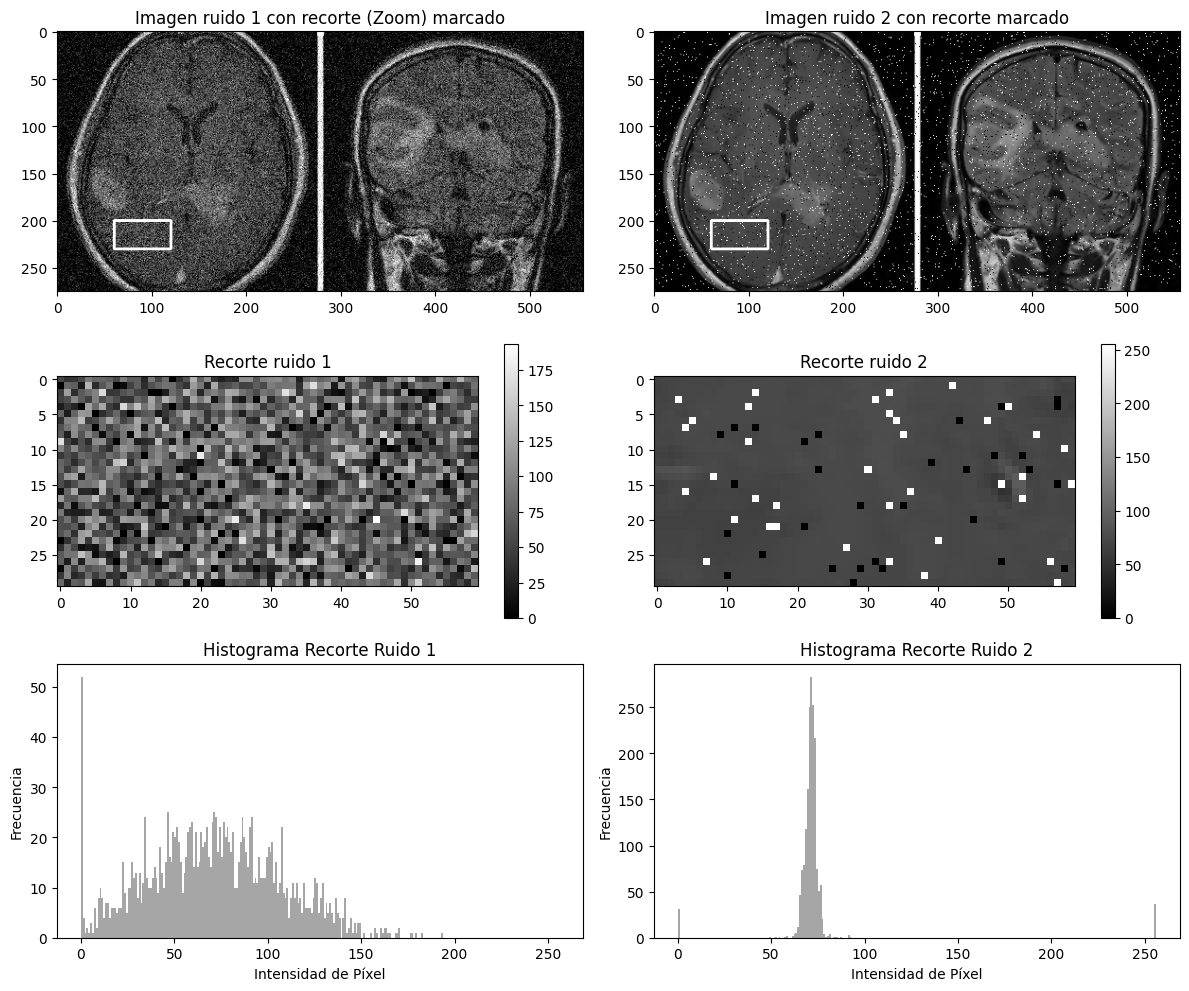

In [5]:
#Graficamos ambas imágenes, sus recortes y los histogramas de los recortes.

# Create copies to draw rectangles on without modifying original images
imagen_ruido1_bordered = imagen_ruido1.copy()
imagen_ruido2_bordered = imagen_ruido2.copy()

# Define color and thickness for the border
color = (255, 255, 255) # color blanco in RGB format
thickness = 2 # Border thickness

# Draw rectangle on the copies
cv2.rectangle(imagen_ruido1_bordered, (x1, y1), (x2, y2), color, thickness)
cv2.rectangle(imagen_ruido2_bordered, (x1, y1), (x2, y2), color, thickness)
#####################################################
plt.figure(figsize=(12, 10)) # Adjusted figure size for 3 rows

# First row: Bordered original images
plt.subplot(321), plt.imshow(imagen_ruido1_bordered, cmap = 'gray')
plt.title('Imagen ruido 1 con recorte (Zoom) marcado')
plt.subplot(322), plt.imshow(imagen_ruido2_bordered, cmap = 'gray')
plt.title('Imagen ruido 2 con recorte marcado')

# Second row: Cutouts
plt.subplot(323), plt.imshow(recorte_ruido1, cmap = 'gray')
plt.colorbar()
plt.title('Recorte ruido 1')
plt.subplot(324), plt.imshow(recorte_ruido2, cmap = 'gray')
plt.colorbar()
plt.title('Recorte ruido 2')

# Third row: Histograms of cutouts
plt.subplot(325)
plt.hist(recorte_ruido1.ravel(), bins=256, range=[0,256], color='gray', alpha=0.7)
plt.title('Histograma Recorte Ruido 1')
plt.xlabel('Intensidad de Píxel')
plt.ylabel('Frecuencia')

plt.subplot(326)
plt.hist(recorte_ruido2.ravel(), bins=256, range=[0,256], color='gray', alpha=0.7)
plt.title('Histograma Recorte Ruido 2')
plt.xlabel('Intensidad de Píxel')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

In [6]:
print(recorte_ruido2[0:10,0:15])

[[ 66  68  69  69  70  70  70  70  70  69  71  72  71  71  72]
 [ 65  67  69  70  70  70  70  70  71  71  73  73  73  73  73]
 [ 66  67  69  70  70  70  70  71  71  73  73  73  73  73 255]
 [ 68  67  68 255  70  70  72  72  72  73  73  73  73  73  74]
 [ 68  69  70  70  69  71  73  74  73  73  73  73  73 255  74]
 [ 67  70  72  69  68  71  74  75  74  73  73  73  73  73  74]
 [ 68  70  71  71  71 255  72  73  73  73  73  73  73  73  72]
 [ 70  71  71  72 255  73  73  72  72  72  72   0  72  71   0]
 [ 70  70  69  71  73  73  73  72  71   0  71  71  70  70  69]
 [ 71  69  69  71  72  72  72  73  72  73  72  71  70 255  70]]


### Histogramas de los Recortes

#Filtros

Transformaciones que utilizan el vecindario de cada pixel.

Sirven por ejemplo:
- para suavizar (mejorar,restaurar) una imagen: quitar ruido/ interferencias,
- mejorar una segmentación (por binarizado)
- detectar bordes

## Vecindario

Existen vecindarios de varios órdenes.
 - Los de 1er orden tienen 4 vecinos
 -El de segundo orden tiene 8 vecinos (ventana 3x3, central y 8 vecinos)
 - Luego hay vecindarios definidos por ventanas 5x5, 7x7, etc

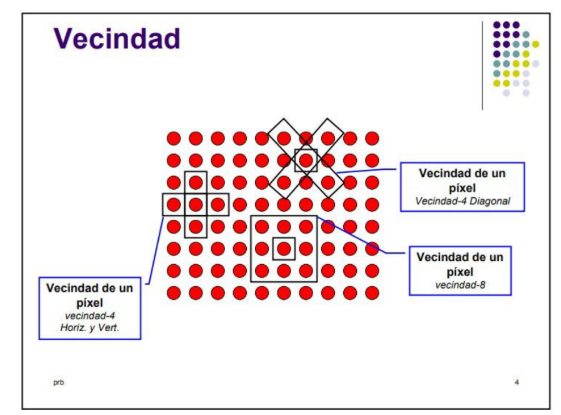



## Filtrado

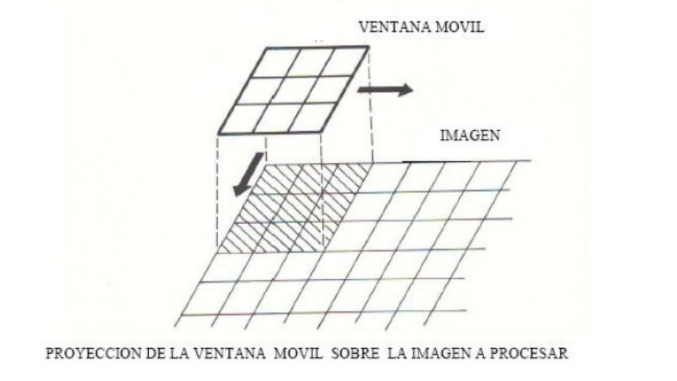

### Tipos de Filtros:
-Lineales (sumas ponderadas o promedios ponderados)

-No lineales (de orden: máximo, mínimo, mediana)

## Filtros lineales

Se considera un **ventana deslizante** sobre la imagen del tamaño de la matriz de filtrado o kernel.

Se obtiene una nueva imagen en donde para cada ventana considerada se modifica pixel central por la **suma de los pixeles contenidos en la ventana ponderados con los coeficientes (pesos) de la matriz (kernel)**.

- Filtro de media o p promediado
- Filtro Gaussiano
- Filtros de bordes


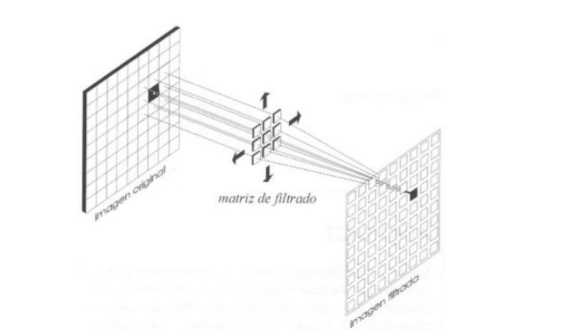

Filminas: Pres2_Filtros_Lineales.pdf

In [7]:
#imagen

In [8]:
#suavisado promedio
#suavizado gaussiano (promedio ponderado)

### Kernel para promediado

In [9]:
n=5
kernel= np.ones ((n,n))/(n**2) #kernel para promedio nxn
print('Kernel=', kernel)

Kernel= [[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]


In [ ]:
# Hacemos la correlación/convolución:
imagen_prom_ruido1 = cv2.filter2D(imagen_ruido1,-1,kernel) #El -1 (ddepth) indica que la salida será del mismo tipo que la entrada
imagen_prom_ruido2 = cv2.filter2D(imagen_ruido2,-1,kernel)


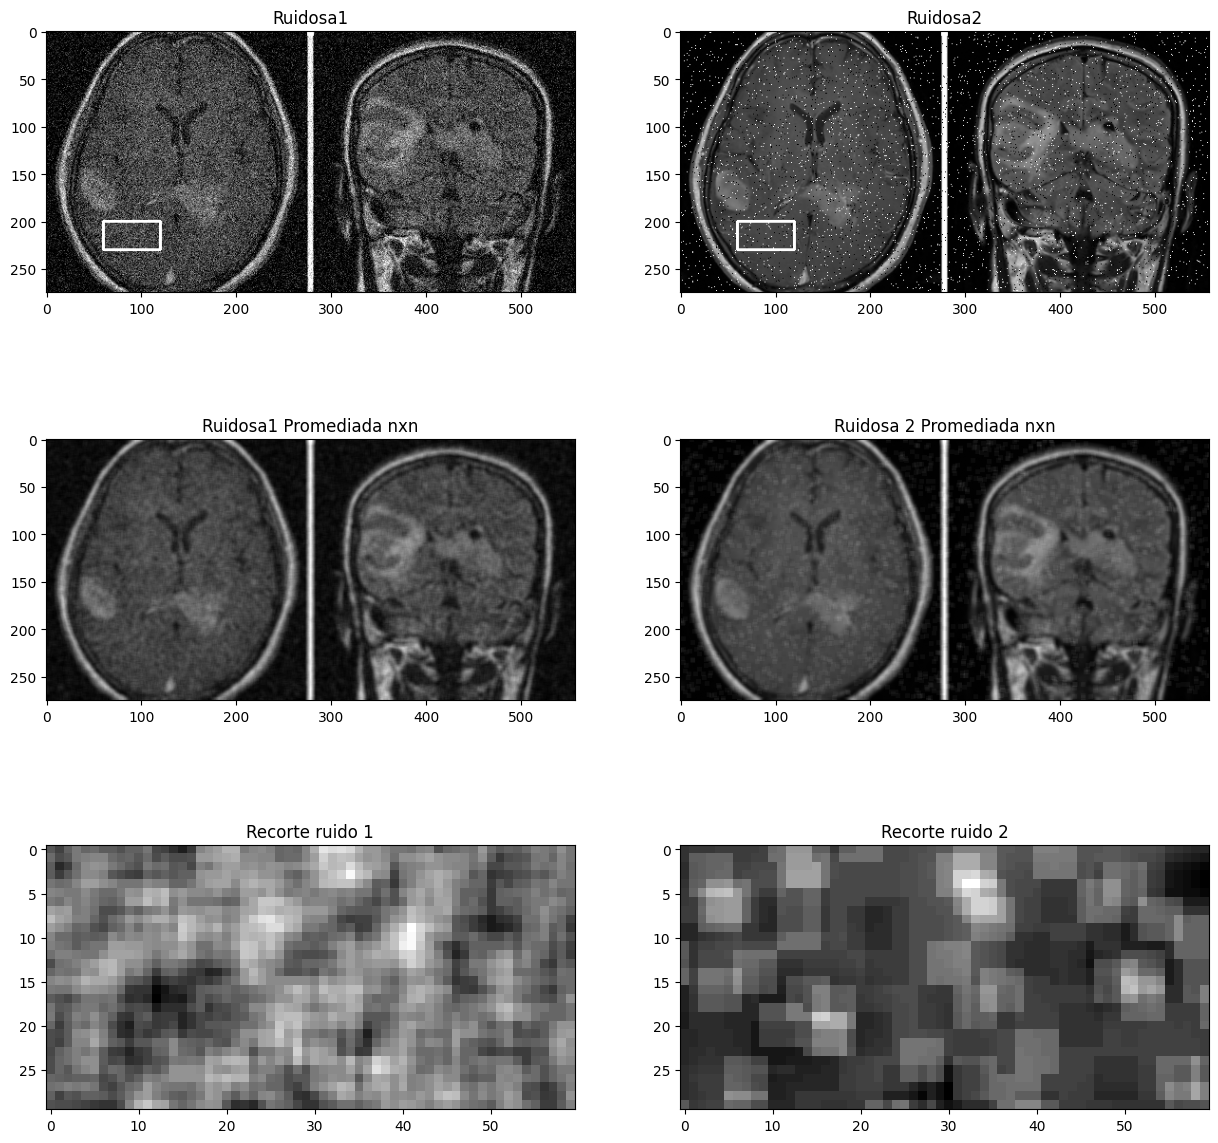

In [19]:
#Visualizamos
recorte_prom_ruido1 = imagen_prom_ruido1[y1:y2, x1:x2]
recorte_prom_ruido2 = imagen_prom_ruido2[y1:y2, x1:x2]

plt.figure(figsize=(15,15))
plt.subplot(321),plt.imshow(imagen_ruido1_bordered,cmap='gray'),plt.title('Ruidosa1')
plt.subplot(323),plt.imshow(imagen_prom_ruido1,cmap='gray'),plt.title('Ruidosa1 Promediada nxn')
plt.subplot(322),plt.imshow(imagen_ruido2_bordered,cmap='gray'),plt.title('Ruidosa2')
plt.subplot(324),plt.imshow(imagen_prom_ruido2,cmap='gray'),plt.title('Ruidosa 2 Promediada nxn')
plt.subplot(325), plt.imshow(recorte_prom_ruido1, cmap = 'gray'),plt.title('Recorte ruido 1')
plt.subplot(326), plt.imshow(recorte_prom_ruido2, cmap = 'gray'),plt.title('Recorte ruido 2')


plt.show()

### Filtro Gaussiano

In [ ]:
# Aplicamos el filtro Gaussiano
# Usamos un kernel de 5x5 y desviaciones estándar 0 (OpenCV las calcula automáticamente)
ng=5 # TAMAÑO DEL KERNEL GAUSSIANO

imagen_gauss_ruido1 = cv2.GaussianBlur(imagen_ruido1, (ng, ng), 1.5,1.5)
imagen_gauss_ruido2 = cv2.GaussianBlur(imagen_ruido2, (ng, ng), 1.5,1.5)


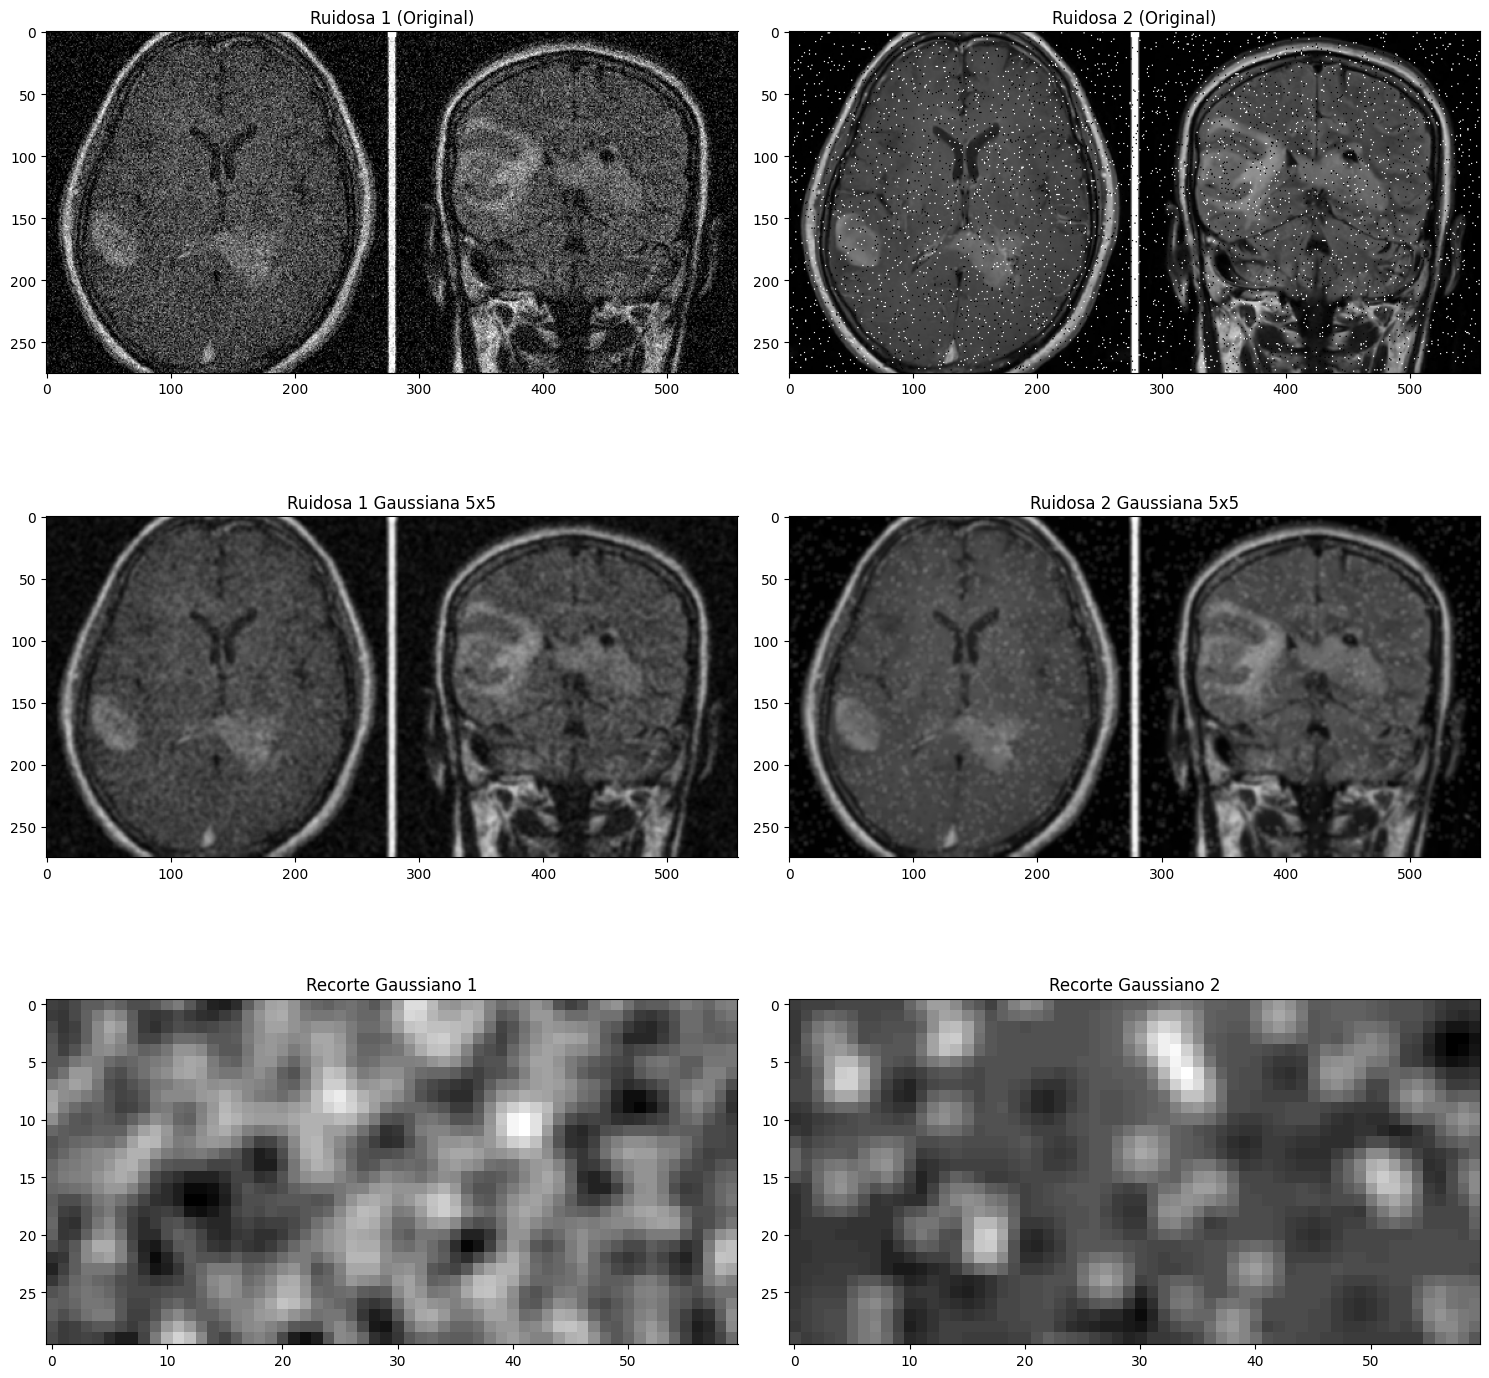

In [11]:
#Visualizamos
# Extraemos los recortes de las imágenes gaussianas
recorte_gauss_ruido1 = imagen_gauss_ruido1[y1:y2, x1:x2]
recorte_gauss_ruido2 = imagen_gauss_ruido2[y1:y2, x1:x2]

plt.figure(figsize=(15, 15))

plt.subplot(321), plt.imshow(imagen_ruido1, cmap='gray'), plt.title('Ruidosa 1 (Original)')
plt.subplot(322), plt.imshow(imagen_ruido2, cmap='gray'), plt.title('Ruidosa 2 (Original)')

plt.subplot(323), plt.imshow(imagen_gauss_ruido1, cmap='gray'), plt.title('Ruidosa 1 Gaussiana 5x5')
plt.subplot(324), plt.imshow(imagen_gauss_ruido2, cmap='gray'), plt.title('Ruidosa 2 Gaussiana 5x5')

plt.subplot(325), plt.imshow(recorte_gauss_ruido1, cmap='gray'), plt.title('Recorte Gaussiano 1')
plt.subplot(326), plt.imshow(recorte_gauss_ruido2, cmap='gray'), plt.title('Recorte Gaussiano 2')

plt.tight_layout()
plt.show()

### Kernel para detección de Bordes (paso alto):
Para encontrar bordes/cambios se usan máscaras de diferencia: Prewit por ej.

**Filminas: Pres2_Filtros_Bordes_Lineales.pdf**

#### Kernels Prewitt

In [12]:
#máscara/kernel Prewitt 3x3:
#Para Bordes Diagonales
KPD=np.array([[1, 1, 0], [1, 0, -1], [0, -1, -1]])
print(KPD)
print('Notar que la suma de los coeficientes da: ', np.sum(KPD))

[[ 1  1  0]
 [ 1  0 -1]
 [ 0 -1 -1]]
Notar que la suma de los coeficientes da:  0


In [13]:
#Para bordes Verticales:
KPV= np.array([[1, 0, -1], [1, 0, -1], [1, 0, -1]])
print(KPV)
print('La suma de los coeficientes da: ', np.sum(KPV))

[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]
La suma de los coeficientes da:  0


In [14]:
#Para Bordes Horizontales
KPH= np.array([[1, 1, 1], [0, 0, 0], [-1, -1, -1]])
print(KPH)
print('La suma de los coeficientes da: ', np.sum(KPH))

[[ 1  1  1]
 [ 0  0  0]
 [-1 -1 -1]]
La suma de los coeficientes da:  0


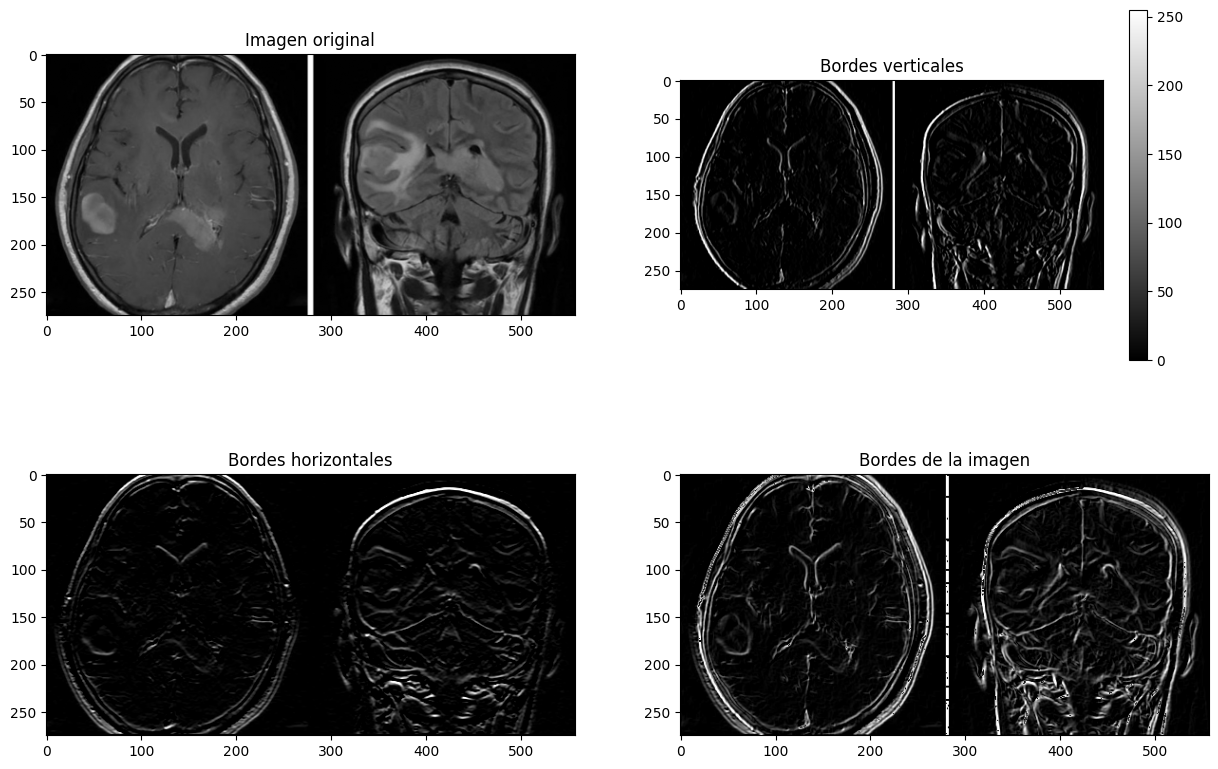

Notar la importancia del tipo de datos en este caso


In [15]:
OP_v=cv2.filter2D(imagen_sin_ruido, -1, KPV )   #Buscar bordes verticales de la imagen.
OP_h=cv2.filter2D(imagen_sin_ruido, -1, KPH  )    #Buscar bordes horizontales de la imagen
Bordes= abs(OP_v)+abs(OP_h) #fusion de bordes

plt.figure(figsize=(15,10))
plt.subplot(221),plt.imshow(imagen_sin_ruido,cmap='gray'),plt.title('Imagen original')
plt.subplot(222),plt.imshow(abs(OP_v),cmap='gray'),plt.title('Bordes verticales')
plt.colorbar()
plt.subplot(223),plt.imshow(abs(OP_h),cmap='gray'),plt.title('Bordes horizontales')
#plt.colorbar()
plt.subplot(224),plt.imshow(Bordes,cmap='gray'),plt.title('Bordes de la imagen')
plt.show()

print('Notar la importancia del tipo de datos en este caso')

#### Kernel Sobel

In [16]:
#Sobel para bordes Verticales:
KSV= np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])
print(KSV)

[[ 1  0 -1]
 [ 2  0 -2]
 [ 1  0 -1]]


#### Kernels Laplacianos

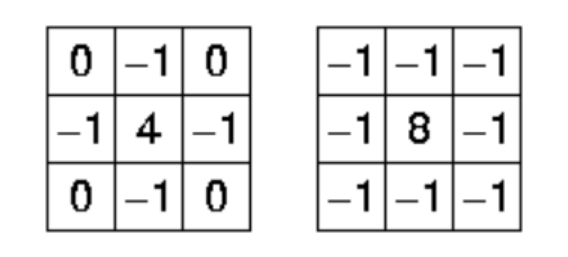

#### CONVOLUCIÓN

Al filtrado (lineal) también se lo llama CONVOLUCIÓN (de la imagen original con el kernel flipeado). **Este concepto (Filtros lineales - Convolución) está relacionado a las redes neuronales convolucionales que verán en Introducción a Redes Neuronales.**


## Filtros no lineales

También considera una **ventana deslizante**, pero no calcula suma ponderada sino el mínimo máximo o mediana de los pixeles de la ventana

ver **Pres4_Filtros_Orden_no_lineales.pdf**

El filtro de mediana sirve para suavisar, es demandante computacionalmente, pero es más robusto a valores extremos (ideal para ruido sal y  pimienta).

El filtro de mínimo (erosión) y el de máximo (dilatación) son ideales para mejorar imágenes binarias, ya que no cambia el tipo de dato (0 y 1)

**Práctica**

### Mediana, para quitar ruido

In [17]:
#Filtro de la mediana nxn, 5x5, 3x3, 7x7...
n= 5

imagen_med_ruido1 = cv2.medianBlur(imagen_ruido1,n) #El n define el area de la ventana: nxn
imagen_med_ruido2 = cv2.medianBlur(imagen_ruido2,n)


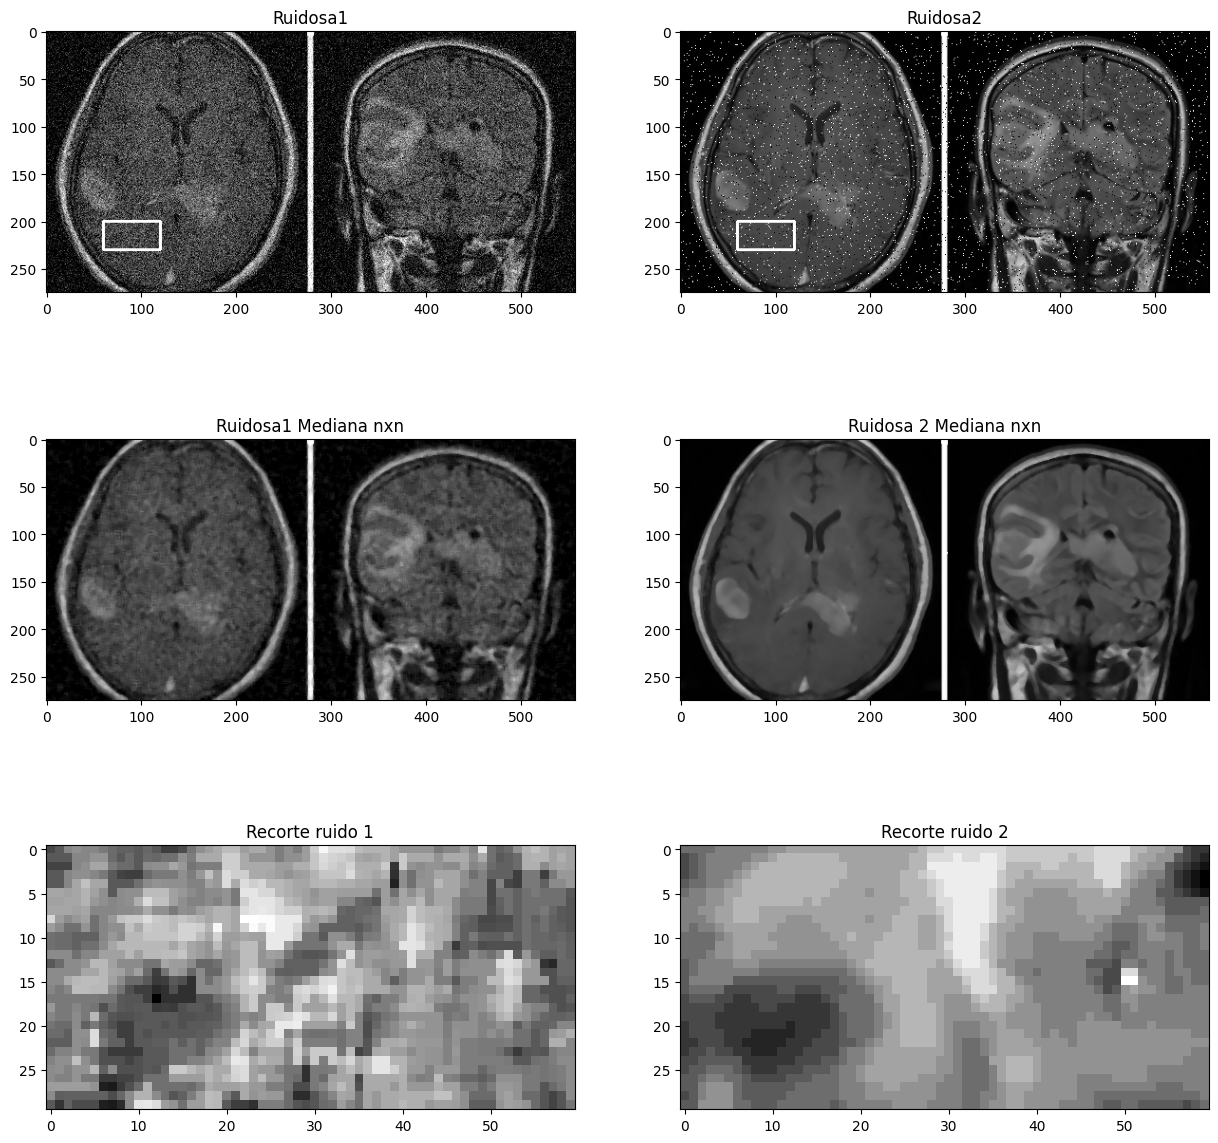

In [20]:
# VISUALIZAMOS
recorte_med_ruido1 = imagen_med_ruido1[y1:y2, x1:x2]
recorte_med_ruido2 = imagen_med_ruido2[y1:y2, x1:x2]

plt.figure(figsize=(15,15))
plt.subplot(321),plt.imshow(imagen_ruido1_bordered,cmap='gray'),plt.title('Ruidosa1')
plt.subplot(323),plt.imshow(imagen_med_ruido1,cmap='gray'),plt.title('Ruidosa1 Mediana nxn')
plt.subplot(322),plt.imshow(imagen_ruido2_bordered,cmap='gray'),plt.title('Ruidosa2')
plt.subplot(324),plt.imshow(imagen_med_ruido2,cmap='gray'),plt.title('Ruidosa 2 Mediana nxn')
plt.subplot(325), plt.imshow(recorte_med_ruido1, cmap = 'gray'),plt.title('Recorte ruido 1')
plt.subplot(326), plt.imshow(recorte_med_ruido2, cmap = 'gray'),plt.title('Recorte ruido 2')

plt.show()

### Mínimo-Erosión  (opcional)

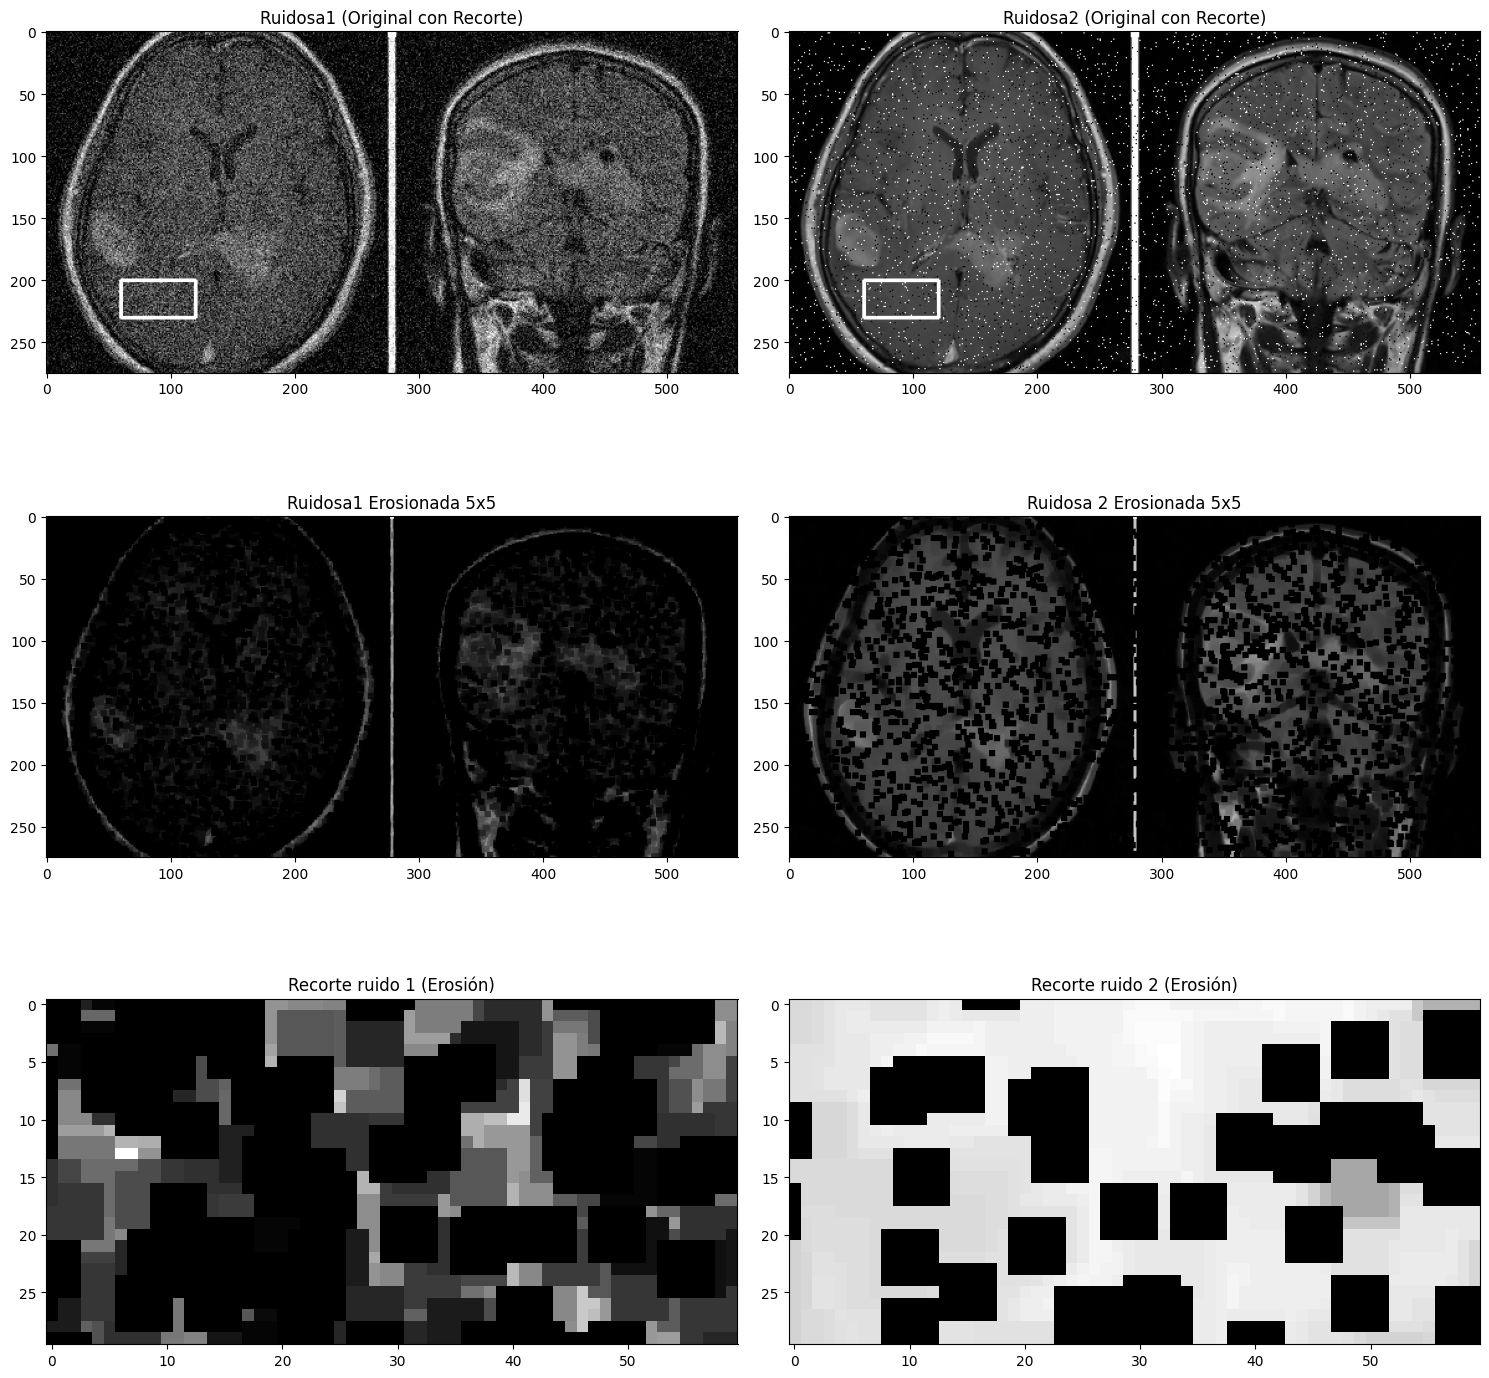

In [21]:
# Definir el kernel para operaciones morfológicas (erosión)
n_morph = 5 # Tamaño del kernel
kernel_morph = np.ones((n_morph, n_morph), np.uint8)

# Aplicar Erosión (filtro de mínimo)
imagen_erode_ruido1 = cv2.erode(imagen_ruido1, kernel_morph, iterations=1)
imagen_erode_ruido2 = cv2.erode(imagen_ruido2, kernel_morph, iterations=1)

# Recortes para las imágenes erosionadas
recorte_erode_ruido1 = imagen_erode_ruido1[y1:y2, x1:x2]
recorte_erode_ruido2 = imagen_erode_ruido2[y1:y2, x1:x2]

plt.figure(figsize=(15,15))
plt.subplot(3,2,1),plt.imshow(imagen_ruido1_bordered,cmap='gray'),plt.title('Ruidosa1 (Original con Recorte)')
plt.subplot(3,2,2),plt.imshow(imagen_ruido2_bordered,cmap='gray'),plt.title('Ruidosa2 (Original con Recorte)')

plt.subplot(3,2,3),plt.imshow(imagen_erode_ruido1,cmap='gray'),plt.title(f'Ruidosa1 Erosionada {n_morph}x{n_morph}')
plt.subplot(3,2,4),plt.imshow(imagen_erode_ruido2,cmap='gray'),plt.title(f'Ruidosa 2 Erosionada {n_morph}x{n_morph}')

plt.subplot(3,2,5), plt.imshow(recorte_erode_ruido1, cmap = 'gray'),plt.title('Recorte ruido 1 (Erosión)')
plt.subplot(3,2,6), plt.imshow(recorte_erode_ruido2, cmap = 'gray'),plt.title('Recorte ruido 2 (Erosión)')

plt.tight_layout()
plt.show()

### Máximo-Dilatación (opcional)

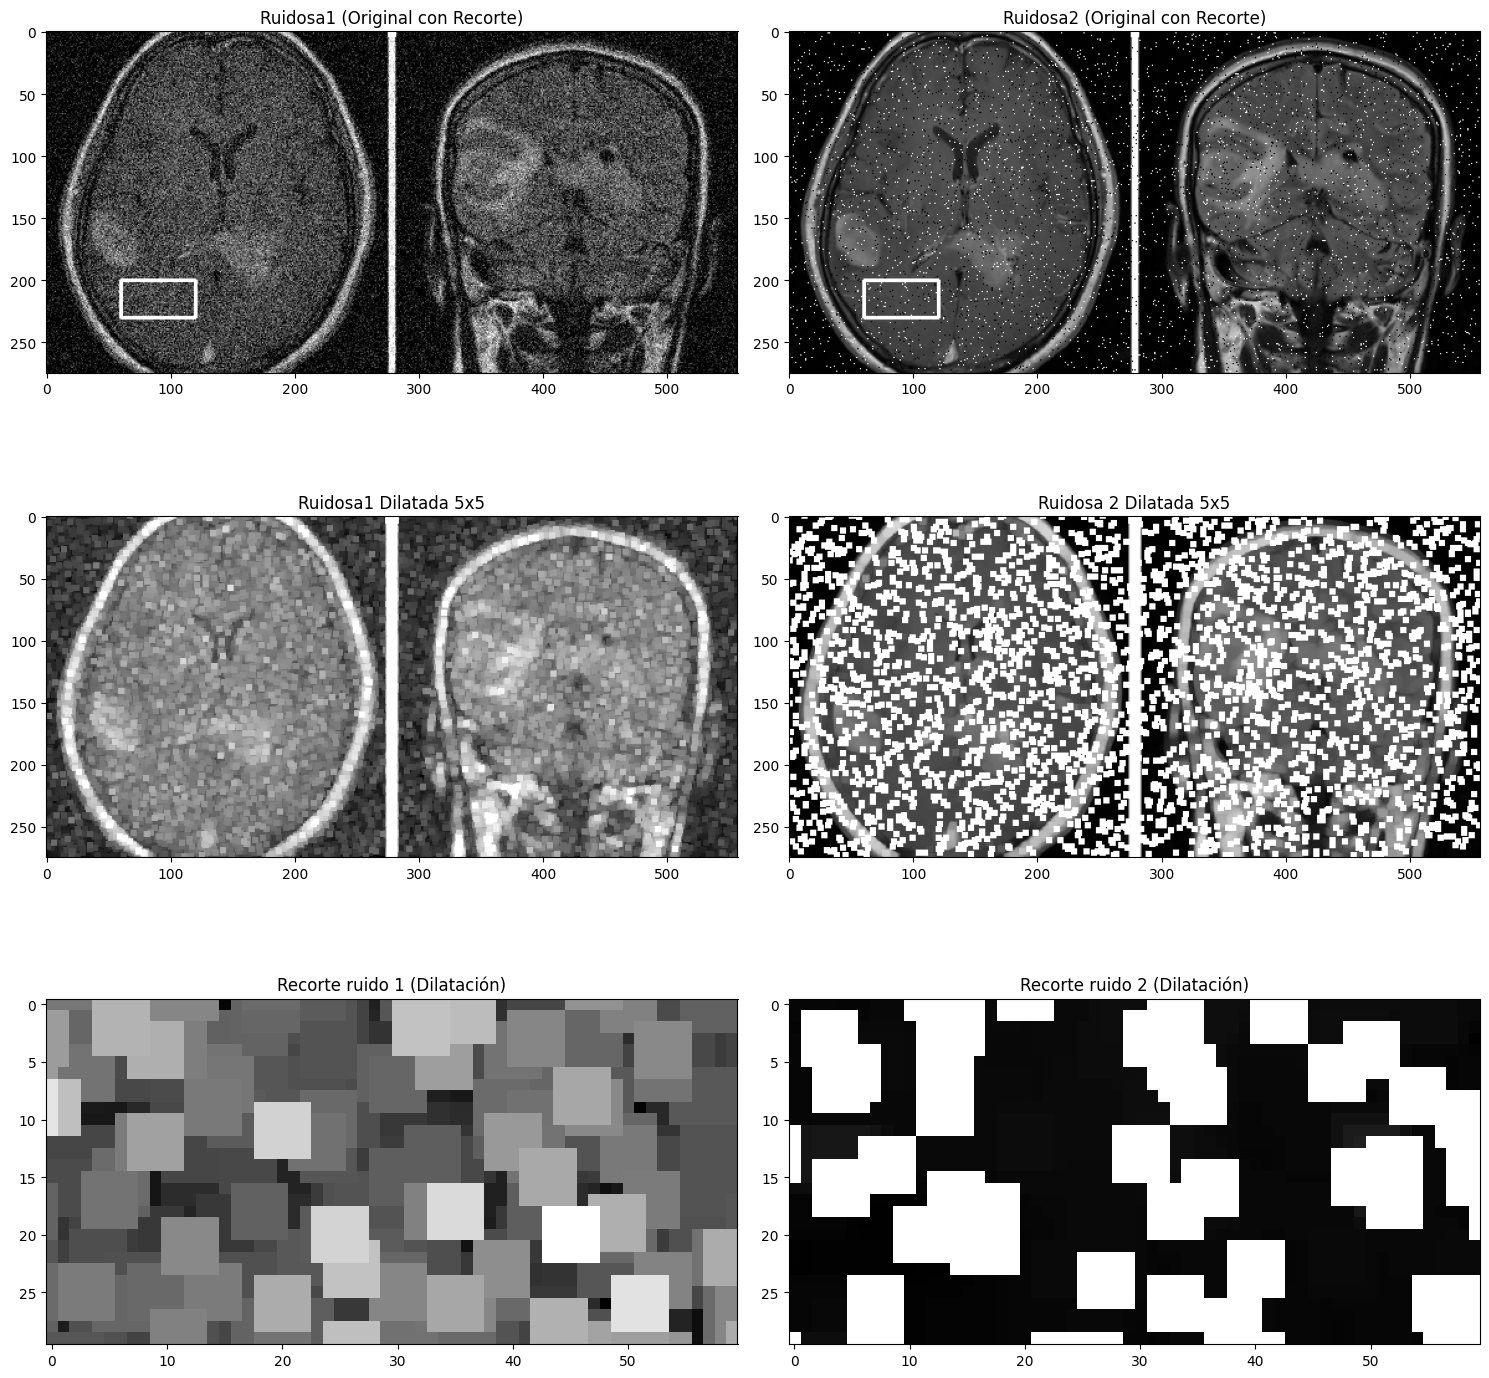

In [22]:
# Definir el kernel para operaciones morfológicas (dilatación)
n_morph = 5 # Tamaño del kernel
kernel_morph = np.ones((n_morph, n_morph), np.uint8)

# Aplicar Dilatación (filtro de máximo)
imagen_dilate_ruido1 = cv2.dilate(imagen_ruido1, kernel_morph, iterations=1)
imagen_dilate_ruido2 = cv2.dilate(imagen_ruido2, kernel_morph, iterations=1)

# Recortes para las imágenes dilatadas
recorte_dilate_ruido1 = imagen_dilate_ruido1[y1:y2, x1:x2]
recorte_dilate_ruido2 = imagen_dilate_ruido2[y1:y2, x1:x2]

plt.figure(figsize=(15,15))
plt.subplot(3,2,1),plt.imshow(imagen_ruido1_bordered,cmap='gray'),plt.title('Ruidosa1 (Original con Recorte)')
plt.subplot(3,2,2),plt.imshow(imagen_ruido2_bordered,cmap='gray'),plt.title('Ruidosa2 (Original con Recorte)')

plt.subplot(3,2,3),plt.imshow(imagen_dilate_ruido1,cmap='gray'),plt.title(f'Ruidosa1 Dilatada {n_morph}x{n_morph}')
plt.subplot(3,2,4),plt.imshow(imagen_dilate_ruido2,cmap='gray'),plt.title(f'Ruidosa 2 Dilatada {n_morph}x{n_morph}')

plt.subplot(3,2,5), plt.imshow(recorte_dilate_ruido1, cmap = 'gray'),plt.title('Recorte ruido 1 (Dilatación)')
plt.subplot(3,2,6), plt.imshow(recorte_dilate_ruido2, cmap = 'gray'),plt.title('Recorte ruido 2 (Dilatación)')

plt.tight_layout()
plt.show()

**Máximo (dilatación), y Mínimo (erosión) no sirve para quitar ruido de monocroma. sirve para binarias, lo veremos en la práctica integral**